# Introduction

This test compares calibration solutions and images produced with different amplitude self-calibration settings. It uses science observation SB87627, with SB87625 for bandpass calibration (-b) and SB86386 for the leakage calibration (-p).

The pipeline ran two self-calibration cycles. The none case used phase-only calibration in both cycles. The other three cases used the same first cycle and applied amplitude and phase solutions in the second cycle, with different flux normalisation settings. Each run used two cycles.

| Case | SELFCAL_NORMALISE_GAINS | SELFCAL_NORMALISE_FLUX |
|---|---|---|
| none | [true,true] | [none,none] |
| median | [true,false] | [none,median] |
| mean | [true,false] | [none,mean] |
| amp | [true,false] | [none,none] |

I compared the calibration solutions, the final primary-beam-corrected mosaics, and the Selavy source catalogues extracted from those mosaics.

# Solutions

I started by looking at the solutions

In [17]:
from datetime import datetime
from pathlib import Path
import re
import shutil
import subprocess

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D


BEAM_ROWS = [
    (35, 34, 33, 32, 31, 30),
    (29, 28, 27, 26, 25, 24),
    (23, 22, 21, 20, 19, 18),
    (17, 16, 15, 14, 13, 12),
    (11, 10, 9, 8, 7, 6),
    (5, 4, 3, 2, 1, 0),
]

CASE_COLORS = {"none": "C0", "median": "C1", "mean": "C2", "amp": "C3"}


def read_gain_table(path, taql):
    """Read the same first gain-array slice as the original code."""

    time_pattern = r"(?m)^(\d{2}-[A-Za-z]{3}-\d{4}/\d{2}:\d{2}:\d{2}\.\d+)\t"
    entry_pattern = r"(?m)^\s*\[0,\s*(\d+),\s*0\]\[(.*)\]\s*$"
    pair_pattern = r"\(([^(),]+),\s*([^(),]+)\)"

    query = f"SELECT TIME, GAIN[0:1,,] AS G, GAIN_VALID[0:1,,] AS V FROM '{path.name}' ORDERBY TIME"
    output = subprocess.check_output([taql, "-ps", "-nopa", query], cwd=path.parent, text=True)

    parts = re.split(time_pattern, output)
    stamps = parts[1::2]
    rows = [re.findall(entry_pattern, row) for row in parts[2::2]]
    entries = [entry for row in rows for entry in row]

    if not stamps or not entries:
        raise ValueError(f"No readable gain rows in {path}")

    times = np.array([datetime.strptime(stamp, "%d-%b-%Y/%H:%M:%S.%f") for stamp in stamps], dtype="datetime64[us]")

    if np.unique(times).size != times.size:
        raise ValueError(f"Duplicate solution times in {path}")

    n_antennas = max(int(antenna) for antenna, _ in entries) + 1
    n_receptors = max(len(re.findall(pair_pattern, values)) for _, values in entries)

    if n_receptors == 0:
        raise ValueError(f"No complex gains in {path}")

    gains = np.full((len(times), n_antennas, n_receptors), np.nan + 1j * np.nan)
    valid = np.zeros(gains.shape, dtype=bool)

    for i, row in enumerate(rows):
        for antenna, values in row:
            antenna = int(antenna)
            pairs = re.findall(pair_pattern, values)

            if pairs:
                gains[i, antenna] = [complex(float(real), float(imag)) for real, imag in pairs]
            else:
                valid[i, antenna] = [value.strip().lower() in ("1", "t", "true") for value in values.split(",")]

    gains[~valid] = np.nan

    return times, gains


def load_gain_solutions(data_dir, cases=None, loop=1, sbid=None, field=None):
    """Load one dataset, or compare named cases underneath data_dir."""

    if data_dir is None:
        raise ValueError("Provide a solution folder as data_dir.")

    data_dir = Path(data_dir).expanduser()

    if not data_dir.is_dir():
        raise FileNotFoundError(data_dir)

    taql = shutil.which("taql") or "/opt/homebrew/bin/taql"

    if taql is None:
        raise FileNotFoundError("taql is not on PATH.")

    cases = (cases,) if isinstance(cases, str) else cases

    if cases is not None:
        cases = tuple(cases)

        if not cases or len(set(cases)) != len(cases):
            raise ValueError("Provide distinct case names, or use cases=None.")

    paths = [data_dir] if data_dir.name == f"caldata_loop{loop}.tab" else sorted(data_dir.rglob(f"caldata_loop{loop}.tab"))
    tables = {}
    identities = set()

    for path in paths:
        match = re.fullmatch(r"selfCal_i\.(.+)\.SB(\d+)\.cont\.\1\.beam(\d+)", path.parent.parent.name)

        if match is None:
            raise ValueError(f"Cannot identify observation and beam from {path}")

        table_field, table_sbid, beam = match.groups()

        if sbid is not None and str(sbid) != table_sbid:
            continue

        if field is not None and field != table_field:
            continue

        if cases is None:
            case = data_dir.name
        else:
            folders = (data_dir.name, *path.relative_to(data_dir).parts[:-1])
            matches = [case for case in cases if case in folders or f"{table_sbid}-{case}" in folders]

            if not matches:
                continue

            if len(matches) > 1:
                raise ValueError(f"More than one case name matches {path}")

            case = matches[0]

        key = (case, int(beam))

        if key in tables:
            raise ValueError("Duplicate beam tables: choose one dataset folder, or supply cases.")

        tables[key] = path
        identities.add((table_sbid, table_field))

    if not tables:
        raise ValueError(f"No selected solution tables under {data_dir}")

    if len(identities) != 1:
        raise ValueError("Multiple observations or fields found. Select one with sbid and field.")

    labels = (data_dir.name,) if cases is None else cases
    missing = [case for case in labels if not any(key[0] == case for key in tables)]

    if missing:
        raise ValueError(f"No tables found for cases: {', '.join(missing)}")

    print(f"Reading {len(tables)} tables ...", flush=True)

    records = {key: read_gain_table(path, taql) for key, path in tables.items()}
    sbid, field = next(iter(identities))
    beams = sorted({beam for _, beam in records})
    n_antennas = max(gains.shape[1] for _, gains in records.values())
    n_receptors = max(gains.shape[2] for _, gains in records.values())
    start = min(times[0] for times, _ in records.values())

    print(f"SB{sbid}: {len(beams)} beams, {n_antennas} antennas, {n_receptors} receptors loaded.")

    return dict(records=records, cases=labels, beams=beams, n_antennas=n_antennas, n_receptors=n_receptors, start=start, sbid=sbid, field=field, loop=loop)


def plot_gain_solutions(data, beam=None, antenna=None, quantities=("amplitude", "phase"), plot_dir="gain_plots"):
    """Plot all gains, one beam, one antenna, or one beam/antenna pair.

    Beam numbers start at 0. Antenna=10 means AK10.
    Use plot_dir=None to show figures without saving.
    """

    quantities = (quantities,) if isinstance(quantities, str) else tuple(quantities)

    if not quantities or any(quantity not in ("amplitude", "phase") for quantity in quantities):
        raise ValueError("Choose amplitude, phase, or both.")

    if beam is not None and beam not in data["beams"]:
        raise ValueError(f"Beam {beam} was not loaded.")

    if antenna is not None and not 1 <= antenna <= data["n_antennas"]:
        raise ValueError(f"Choose antenna 1–{data['n_antennas']}.")

    if antenna is not None and beam is None and not set(data["beams"]).issubset(range(36)):
        raise ValueError("The beam footprint supports beam IDs 00–35.")

    records = {key: record for key, record in data["records"].items() if beam is None or key[1] == beam}
    hours = {key: (times - data["start"]) / np.timedelta64(1, "h") for key, (times, _) in records.items()}
    max_hours = max(max(values[-1] for values in hours.values()), 1e-6)

    cases = data["cases"]
    colors = {case: CASE_COLORS.get(case, f"C{i % 10}") for i, case in enumerate(cases)}
    legend = [Line2D([], [], color=colors[case], label=case) for case in cases]

    output = Path(plot_dir).expanduser() if plot_dir is not None else None

    if output is not None:
        output.mkdir(parents=True, exist_ok=True)

    def finish(fig, quantity, suffix, title, top):
        fig.suptitle(f"SB{data['sbid']} · Loop {data['loop']} · {title}", y=0.985)
        fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=len(cases), frameon=False)
        fig.subplots_adjust(left=0.07, right=0.99, bottom=0.07, top=top, wspace=0.22, hspace=0.45)

        if output is not None:
            fig.savefig(output / f"SB{data['sbid']}_loop{data['loop']}_{quantity}_{suffix}_{'-vs-'.join(cases)}.pdf")

        plt.show()
        plt.close(fig)

    for quantity in quantities:
        transform = np.abs if quantity == "amplitude" else lambda gains: np.angle(gains, deg=True)
        ylabel = "Gain amplitude" if quantity == "amplitude" else "Gain phase (deg)"
        values = {key: transform(gains) for key, (_, gains) in records.items()}

        antenna_slice = slice(None) if antenna is None else slice(antenna - 1, antenna)
        finite = [array[:, antenna_slice, :][np.isfinite(array[:, antenna_slice, :])] for array in values.values()]
        finite = [array for array in finite if array.size]

        if not finite:
            raise ValueError("No valid gains for this selection.")

        low = min(array.min() for array in finite)
        high = max(array.max() for array in finite)
        padding = 0.05 * (high - low) if high > low else 0.05 * max(abs(low), 1)
        low, high = low - padding, high + padding

        def draw(ax, b, ant, receptor):
            has_values = False

            for case in cases:
                key = (case, b)

                if key in values and ant < values[key].shape[1] and receptor < values[key].shape[2]:
                    trace = values[key][:, ant, receptor]
                    has_values |= np.isfinite(trace).any()
                    ax.plot(hours[key], trace, color=colors[case], linewidth=0.8)

            ax.set_xlim(0, max_hours)
            ax.set_ylim(low, high)

            return has_values

        # One beam and antenna: both receptors in the same figure.
        if beam is not None and antenna is not None:
            fig, axes = plt.subplots(data["n_receptors"], 1, sharex=True, sharey=True, figsize=(8, 2.7 * data["n_receptors"]), squeeze=False)

            for receptor, ax in enumerate(axes.flat):
                draw(ax, beam, antenna - 1, receptor)
                ax.set_title(f"Receptor {receptor + 1}", loc="left")
                ax.set_ylabel(ylabel)
                ax.set_xlabel("Hours from first solution")
                ax.tick_params(axis="x", labelbottom=True)

            finish(fig, quantity, f"beam{beam:02d}_AK{antenna:02d}", f"Beam {beam:02d} · AK{antenna:02d} · {ylabel}", 0.82)

            continue

        for receptor in range(data["n_receptors"]):

            # All beams and antennas: fast LineCollection grid.
            if beam is None and antenna is None:
                n_beams = len(data["beams"])
                n_antennas = data["n_antennas"]

                fig, ax = plt.subplots(figsize=(max(8, 0.9 * n_beams), max(6, 0.7 * n_antennas)))

                grid = [[(x, 0), (x, n_antennas)] for x in range(n_beams + 1)]
                grid += [[(0, y), (n_beams, y)] for y in range(n_antennas + 1)]
                ax.add_collection(LineCollection(grid, colors="0.35", linewidths=0.4))

                for case in cases:
                    segments = []

                    for column, b in enumerate(data["beams"]):
                        key = (case, b)

                        if key not in values or receptor >= values[key].shape[2]:
                            continue

                        x = column + 0.04 + 0.92 * hours[key] / max_hours

                        for ant in range(values[key].shape[1]):
                            y = n_antennas - 1 - ant + 0.04 + 0.92 * (values[key][:, ant, receptor] - low) / (high - low)
                            segments.append(np.column_stack((x, y)))

                    ax.add_collection(LineCollection(segments, colors=colors[case], linewidths=0.55))

                ax.set_xlim(0, n_beams)
                ax.set_ylim(0, n_antennas)
                ax.set_xticks(np.arange(n_beams) + 0.5, [f"B{b:02d}" for b in data["beams"]])
                ax.set_yticks(n_antennas - 0.5 - np.arange(n_antennas), [f"AK{ant + 1:02d}" for ant in range(n_antennas)])
                ax.xaxis.tick_top()
                ax.tick_params(length=0, labelsize=8)
                ax.set_xlabel(f"Hours from first solution (0–{max_hours:.2f} h per panel)")
                ax.set_ylabel(f"{ylabel} ({low:.4g} to {high:.4g} per panel)")

                finish(fig, quantity, f"all_beams_all_antennas_receptor{receptor + 1}", f"Receptor {receptor + 1} · {ylabel}", 0.90)

                continue

            # One antenna: all beams in the fixed staggered footprint.
            if antenna is not None:
                fig = plt.figure(figsize=(17, 12))
                grid = fig.add_gridspec(6, 13)
                panels = []
                shared = None

                for row, beams in enumerate(BEAM_ROWS):
                    for col, b in enumerate(beams):
                        left = 2 * col + row % 2
                        ax = fig.add_subplot(grid[row, left:left + 2], sharex=shared, sharey=shared)

                        if shared is None:
                            shared = ax

                        panels.append((b, ax))
                        ax.tick_params(axis="x", labelbottom=row == 5)
                        ax.tick_params(axis="y", labelleft=col == 0)

            # One beam: all antennas in a regular grid.
            else:
                ids = range(data["n_antennas"])
                columns = min(6, len(ids))
                rows = (len(ids) + columns - 1) // columns

                fig, axes = plt.subplots(rows, columns, sharex=True, sharey=True, figsize=(max(8, 2.8 * columns), max(4, 2 * rows)), squeeze=False)
                panels = list(zip(ids, axes.flat))

                for ax in list(axes.flat)[len(ids):]:
                    ax.set_visible(False)

            for index, ax in panels:
                b, ant = (beam, index) if beam is not None else (index, antenna - 1)
                has_values = draw(ax, b, ant, receptor)

                ax.set_title(f"AK{ant + 1:02d}" if beam is not None else f"Beam {b:02d}", fontsize=10)
                ax.tick_params(labelsize=8)

                if not has_values:
                    ax.text(0.5, 0.5, "No valid solutions", transform=ax.transAxes, ha="center", fontsize=8)

            fig.supxlabel("Hours from first solution")
            fig.supylabel(ylabel)

            selection = f"Beam {beam:02d}" if beam is not None else f"AK{antenna:02d}"
            suffix = f"beam{beam:02d}_all_antennas" if beam is not None else f"AK{antenna:02d}_all_beams"

            finish(fig, quantity, f"{suffix}_receptor{receptor + 1}", f"{selection} · Receptor {receptor + 1} · {ylabel}", 0.88)


def summarise_gain_changes(data, reference="none"):
    """Median absolute percentage differences over matched times, antennas and beams.

    Uses the original amplitude and signed-phase percentage definitions.
    Zero reference phases are excluded.
    """

    if reference not in data["cases"]:
        raise ValueError(f"Load the reference case {reference!r} first.")

    summary = {}

    print(f"{'Case vs ' + reference:<18} {'Receptor':>8} {'Median |Δamp| (%)':>19} {'Median |Δphase| (%)':>21}")

    for case in data["cases"]:
        if case == reference:
            continue

        changes = [[[], []] for _ in range(data["n_receptors"])]

        for beam in data["beams"]:
            if (reference, beam) not in data["records"] or (case, beam) not in data["records"]:
                continue

            ref_times, ref_gains = data["records"][reference, beam]
            times, gains = data["records"][case, beam]

            _, ref_rows, case_rows = np.intersect1d(ref_times, times, assume_unique=True, return_indices=True)
            n_antennas = min(ref_gains.shape[1], gains.shape[1])

            for pol in range(min(ref_gains.shape[2], gains.shape[2])):
                ref = ref_gains[ref_rows, :n_antennas, pol]
                current = gains[case_rows, :n_antennas, pol]

                valid = np.isfinite(ref) & np.isfinite(current) & (ref != 0)
                ref, current = ref[valid], current[valid]

                amp_change = 100 * np.abs(np.abs(current) / np.abs(ref) - 1)
                changes[pol][0].append(amp_change)

                ref_phase = np.angle(ref, deg=True)
                phase = np.angle(current, deg=True)
                valid_phase = (ref_phase != 0) & (current != 0)

                phase_change = 100 * np.abs(phase[valid_phase] / ref_phase[valid_phase] - 1)
                changes[pol][1].append(phase_change)

        for pol, (amplitudes, phases) in enumerate(changes):
            amplitudes = np.concatenate(amplitudes) if amplitudes else np.array([])
            phases = np.concatenate(phases) if phases else np.array([])

            amp = np.median(amplitudes) if amplitudes.size else np.nan
            phase = np.median(phases) if phases.size else np.nan

            summary[case, pol + 1] = dict(amplitude_percent=amp, phase_percent=phase, amplitude_samples=amplitudes.size, phase_samples=phases.size)

            print(f"{case:<18} {pol + 1:>8} {amp:>19.6f} {phase:>21.6f}")

    return summary

In [ ]:
data_dir = Path.home() / "Documents/Australia/CSIRO/science_field/sols"
plot_dir = Path.home() / "Documents/Australia/CSIRO/science_field/calibration_comparison_plots"

Reading 144 tables ...
SB87627: 36 beams, 36 antennas, 2 receptors loaded.


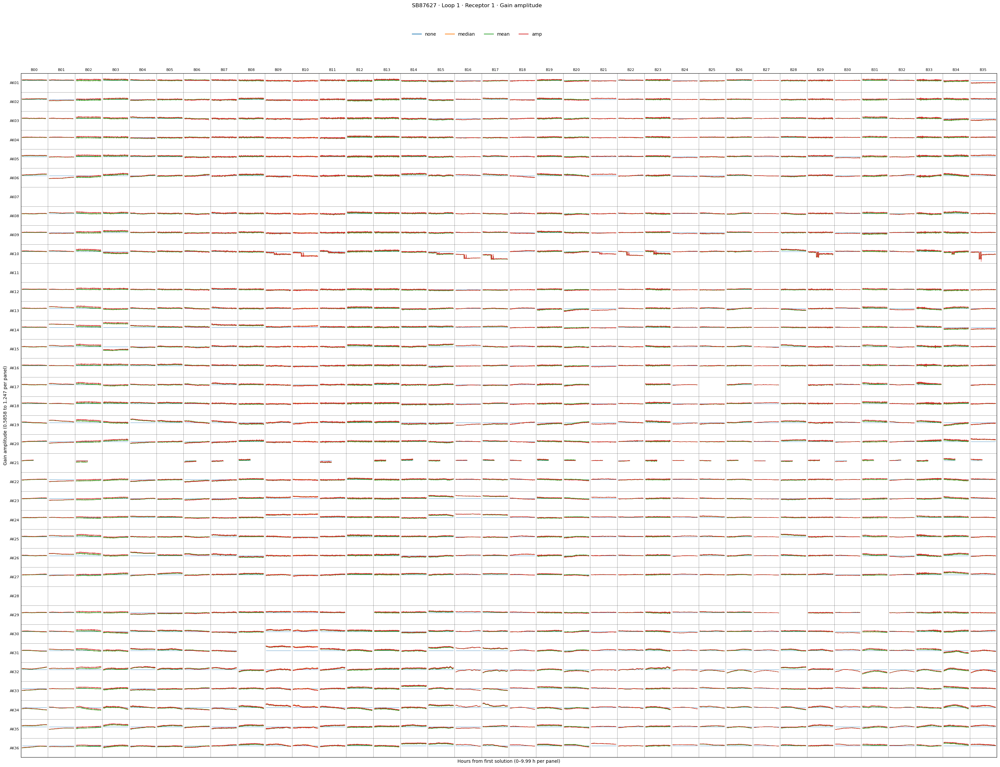

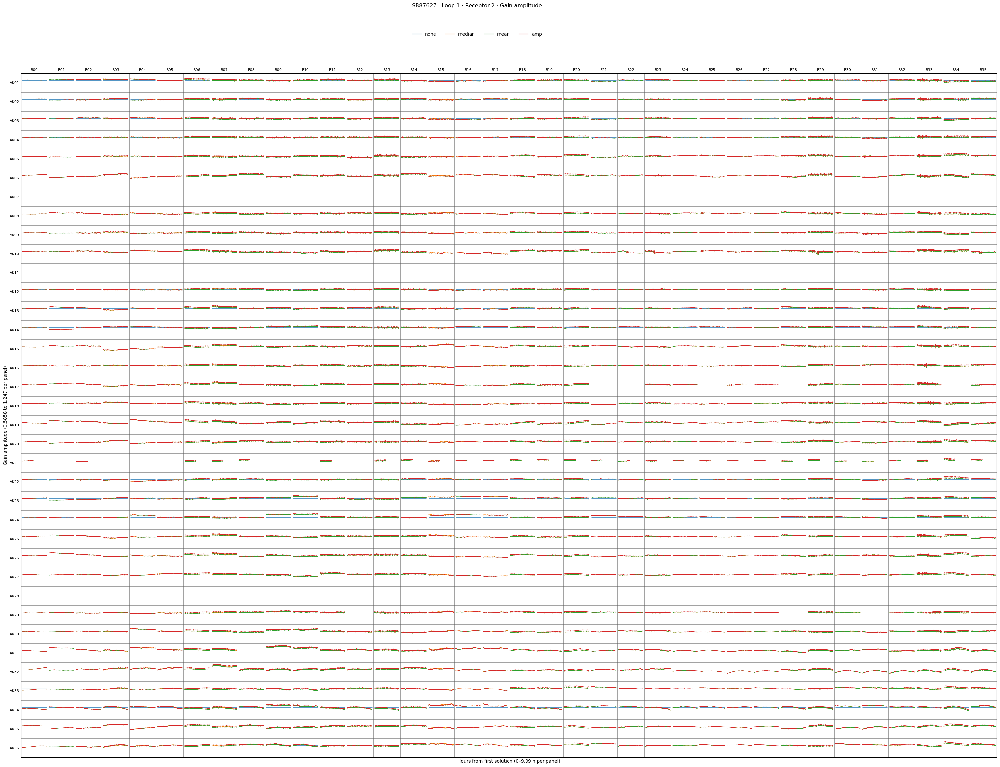

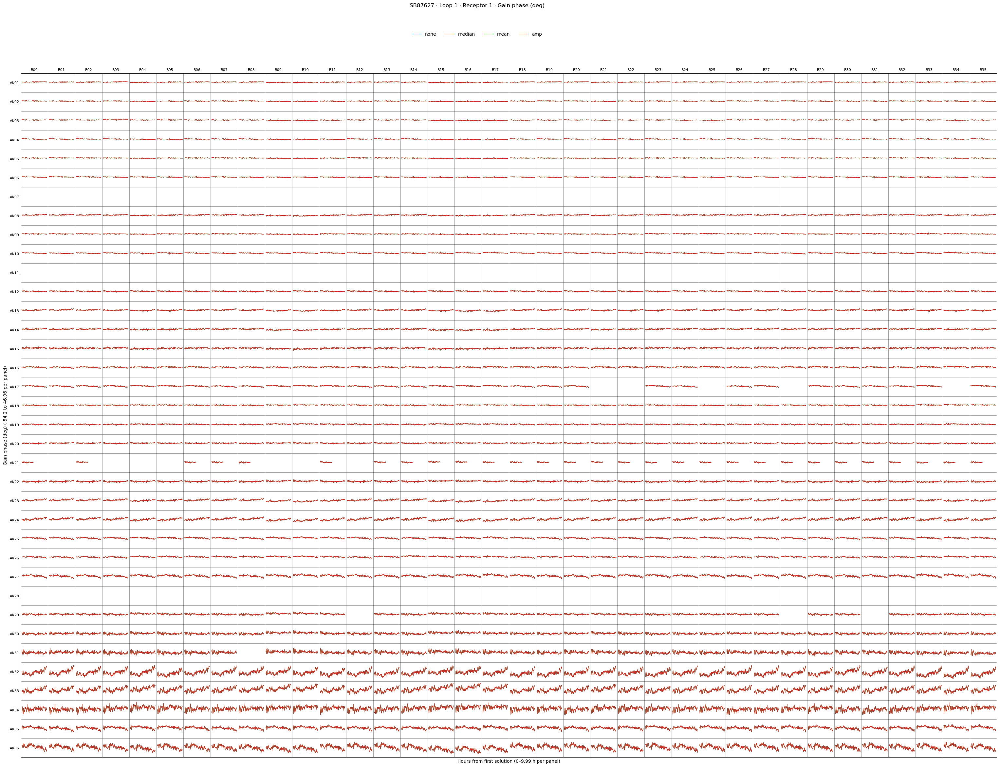

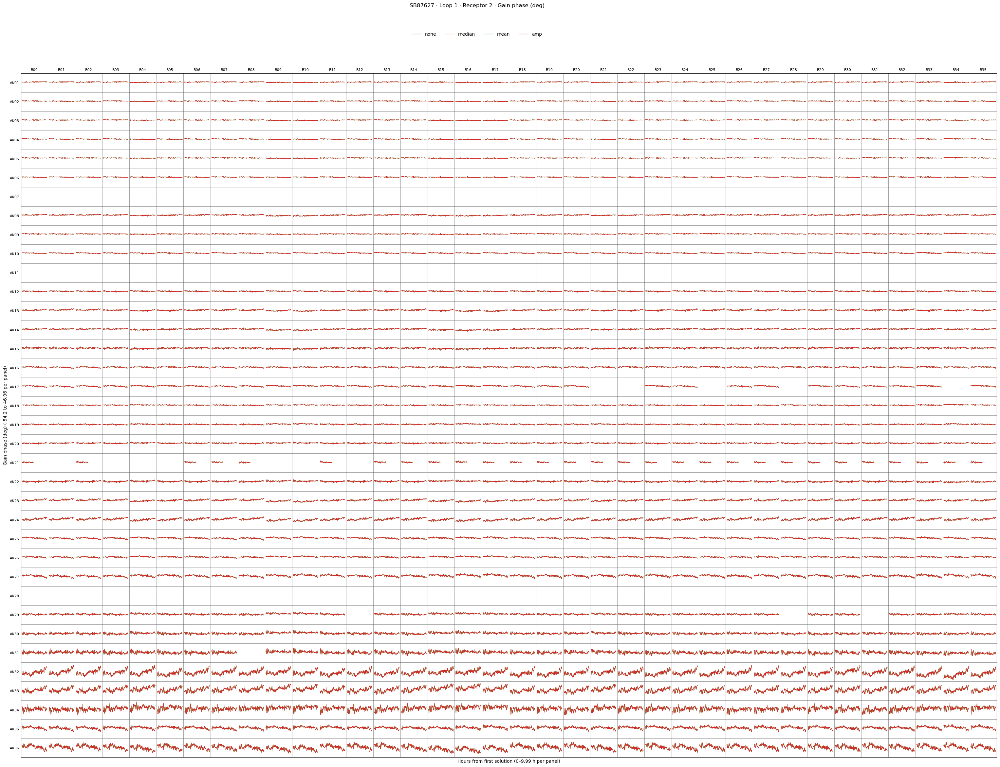

In [ ]:
# All beams and antennas, amplitude and phase.
solutions = load_gain_solutions(data_dir, cases=("none", "median", "mean", "amp"))
plot_gain_solutions(solutions, plot_dir=plot_dir)

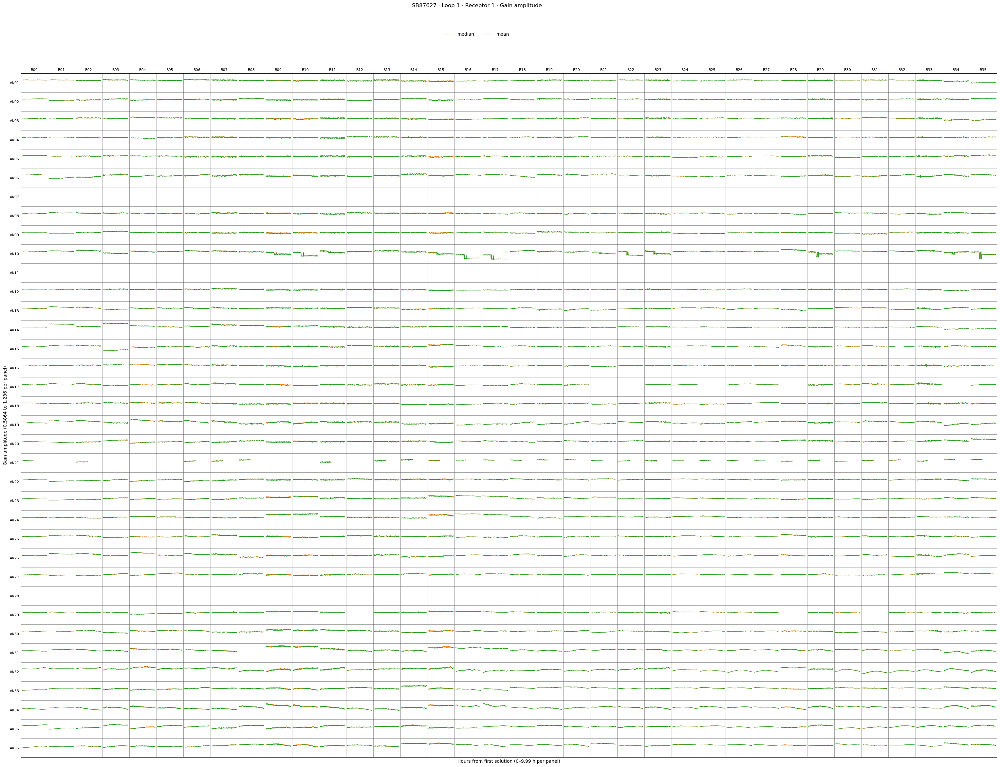

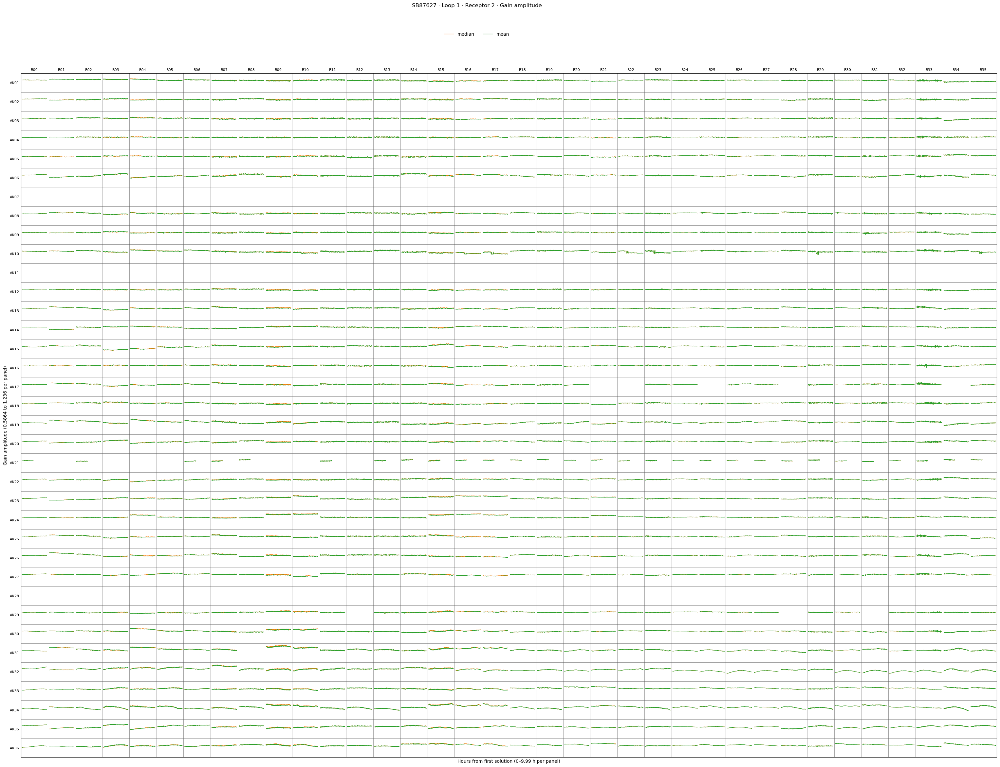

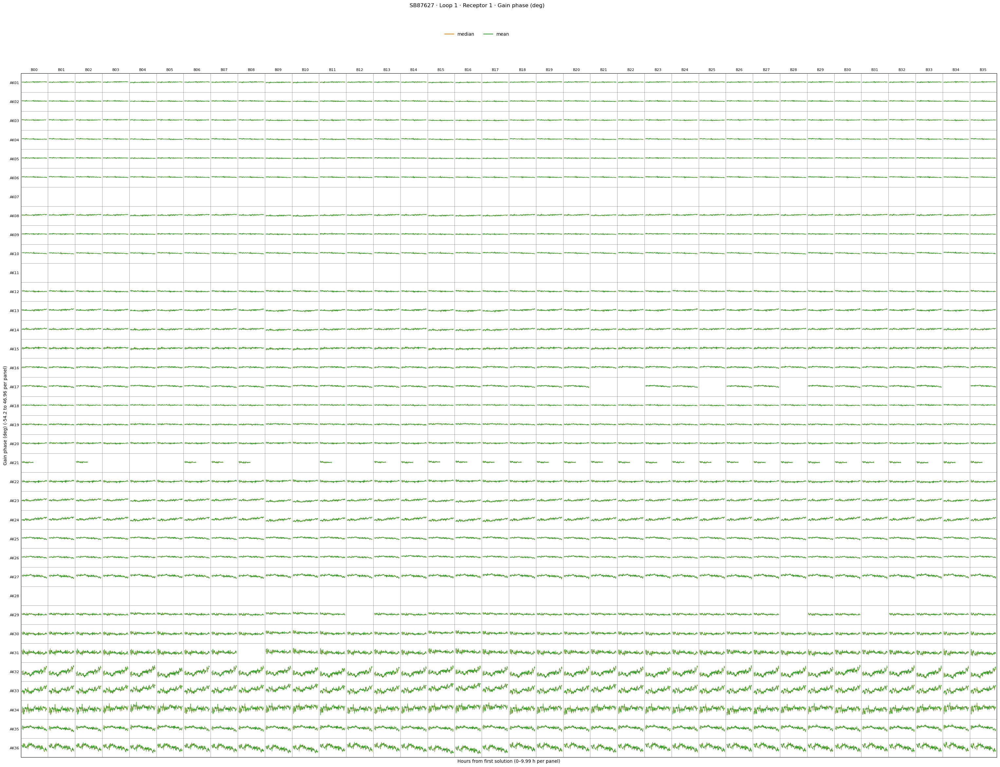

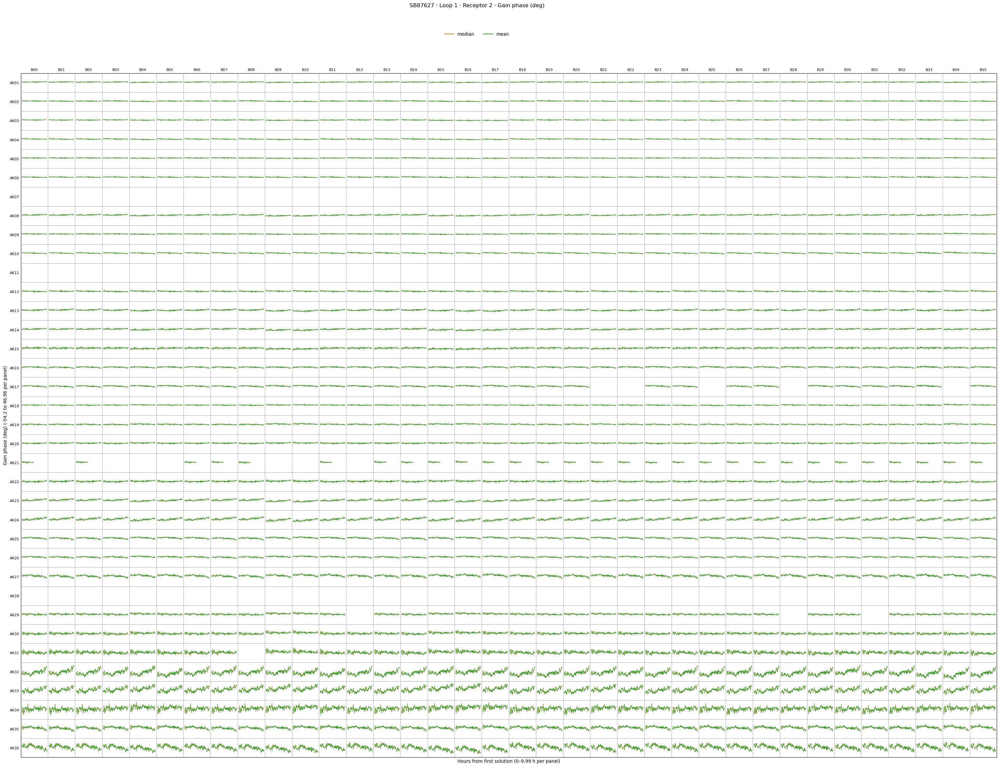

In [20]:
selected = solutions.copy()
selected["cases"] = ("median", "mean")
selected["records"] = {key: record for key, record in solutions["records"].items() if key[0] in selected["cases"]}

plot_gain_solutions(selected, plot_dir=plot_dir)

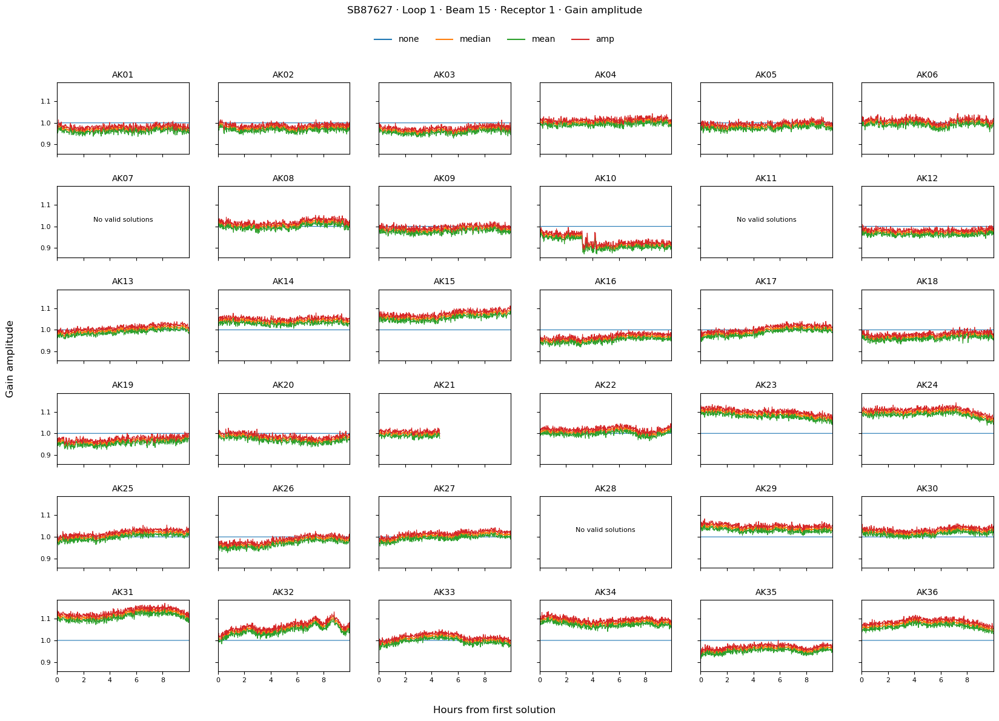

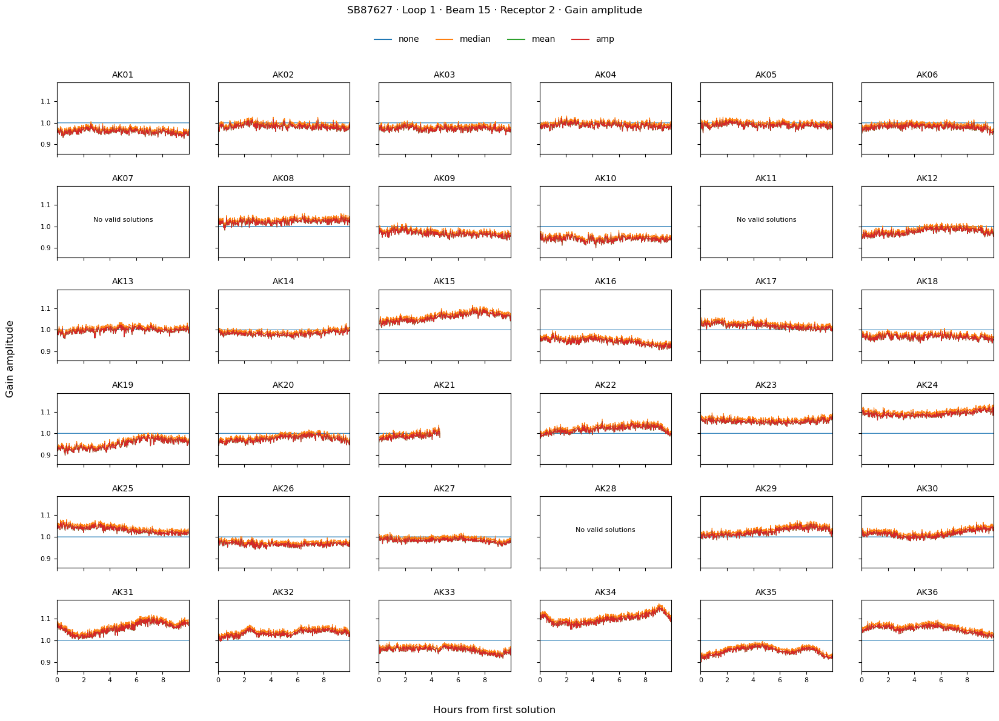

In [21]:
# One beam, all antennas.
plot_gain_solutions(solutions, beam=15, quantities="amplitude", plot_dir=plot_dir)

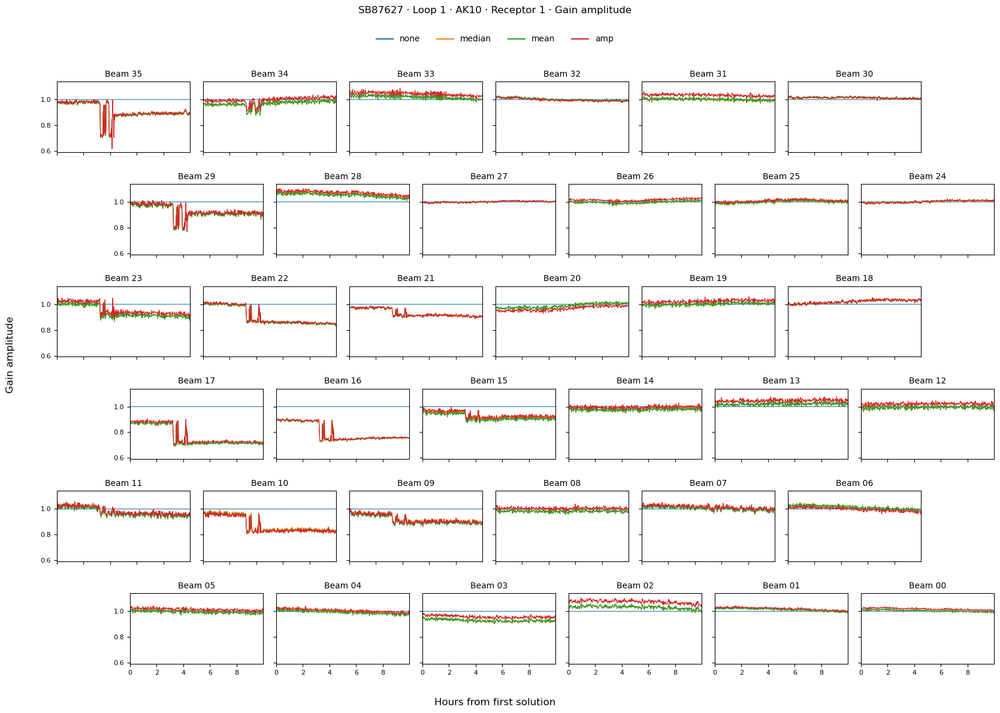

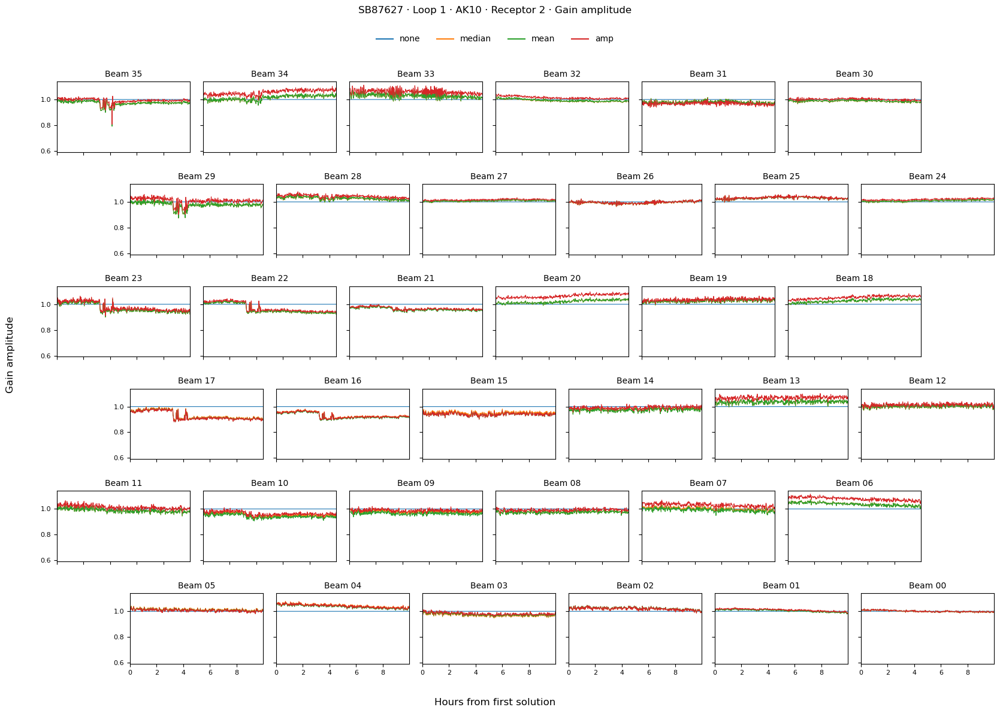

In [22]:
# One antenna, all beams in the beam footprint.
plot_gain_solutions(solutions, antenna=10, quantities="amplitude", plot_dir=plot_dir)

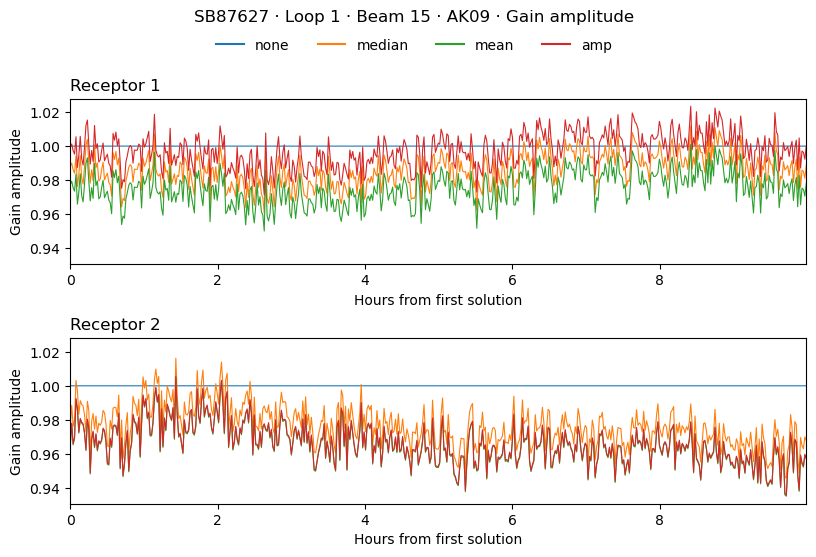

In [23]:
# One beam and antenna.
plot_gain_solutions(solutions, beam=15, antenna=9, quantities="amplitude", plot_dir=plot_dir)

In [24]:
# Summary last.
gain_summary = summarise_gain_changes(solutions)

Case vs none       Receptor   Median |Δamp| (%)   Median |Δphase| (%)
median                    1            1.504640              0.000143
median                    2            1.465377              0.000144
mean                      1            1.559164              0.000143
mean                      2            1.524562              0.000141
amp                       1            2.121551              0.000176
amp                       2            2.119668              0.000182


# Flux comparison

I compare the integrated flux densities measured by Selavy with those from RACS. To reduce false matches, I select isolated Selavy sources with an SNR > 10 and a single RACS match within 1.5 arcseconds. For each matched source, I plot the ratio of the Selavy to RACS integrated flux density against the RACS integrated flux density.

In [27]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, search_around_sky
from astropy.table import Table


CSIRO = Path.home() / "Documents/Australia/CSIRO"
CATALOGUES = CSIRO / "science_field/sourceCatalogues"
RACS_FILE = CSIRO / "science_field/skyModels/RACS-low3_flint_skymodel.fits.gz"
PLOT_DIR = CSIRO / "science_field/calibration_comparison_plots"

MOSAIC_CATALOGUE = "selavy-image.i.EMU_1014-46.SB87627.cont.taylor.0.restored.conv.components.txt"

CASE_COLORS = {
    "none": "C0",
    "median": "C1",
    "mean": "C2",
    "amp": "C3",
}

MATCH_ARCSEC = 1.5
ISOLATION_ARCSEC = 45.0
MIN_SNR = 10.0


def read_selavy(path):
    lines = path.read_text().splitlines()
    header = next(line[1:].split() for line in lines if line.startswith("#") and "component_id" in line)
    entries = []

    for line in lines:
        if not line.strip() or line.lstrip().startswith("#"):
            continue

        values = dict(zip(header, line.split()))

        try:
            peak = float(values["flux_peak"])
            rms = float(values["rms_image"])
            entry = {
                "name": values["component_name"],
                "ra": float(values["ra_deg_cont"]),
                "dec": float(values["dec_deg_cont"]),
                "peak": peak,
                "integrated": float(values["flux_int"]),
                "snr": peak / rms if rms > 0 else 0.0,
                "has_siblings": values["has_siblings"] == "1",
            }
        except (KeyError, ValueError):
            continue

        entries.append(entry)

    selected = [entry for entry in entries if entry["snr"] > MIN_SNR]
    return entries, selected


def read_racs_near_catalogues(catalogues):
    targets = [entry for catalogue in catalogues for entry in catalogue]
    if not targets:
        raise ValueError("No Selavy sources passed the SNR cut.")

    target_ra = np.array([entry["ra"] for entry in targets])
    target_dec = np.array([entry["dec"] for entry in targets])
    dec_pad = ISOLATION_ARCSEC / 3600
    ra_pad = dec_pad / np.cos(np.deg2rad(np.max(np.abs(target_dec))))

    racs = Table.read(RACS_FILE)
    ra = np.asarray(racs["RA"], dtype=float)
    dec = np.asarray(racs["Dec"], dtype=float)
    flux = np.asarray(racs["Total_flux"], dtype=float)

    keep = (
        (dec >= target_dec.min() - dec_pad)
        & (dec <= target_dec.max() + dec_pad)
        & (ra >= target_ra.min() - ra_pad)
        & (ra <= target_ra.max() + ra_pad)
        & np.isfinite(flux) & (flux > 0)
    )
    return racs[keep]


def find_matches(racs, all_entries, selected_entries):
    if not selected_entries or len(racs) == 0:
        return {}

    racs_coords = SkyCoord(ra=np.asarray(racs["RA"]) * u.deg, dec=np.asarray(racs["Dec"]) * u.deg)
    all_coords = SkyCoord(ra=[entry["ra"] for entry in all_entries] * u.deg, dec=[entry["dec"] for entry in all_entries] * u.deg)
    selected_coords = SkyCoord(ra=[entry["ra"] for entry in selected_entries] * u.deg, dec=[entry["dec"] for entry in selected_entries] * u.deg)

    ri, ci, separation, _ = search_around_sky(racs_coords, selected_coords, MATCH_ARCSEC * u.arcsec)
    near_ri, near_ci, _, _ = search_around_sky(racs_coords, selected_coords, ISOLATION_ARCSEC * u.arcsec)
    _, all_near_ci, _, _ = search_around_sky(all_coords, selected_coords, ISOLATION_ARCSEC * u.arcsec)

    racs_matches = np.bincount(ri, minlength=len(racs))
    selected_matches = np.bincount(ci, minlength=len(selected_entries))
    racs_near = np.bincount(near_ri, minlength=len(racs))
    selected_near = np.bincount(near_ci, minlength=len(selected_entries))
    all_near = np.bincount(all_near_ci, minlength=len(selected_entries))
    matches = {}

    for racs_index, selected_index, distance in zip(ri, ci, separation.arcsec):
        entry = selected_entries[selected_index]

        if racs_matches[racs_index] != 1 or selected_matches[selected_index] != 1:
            continue
        if racs_near[racs_index] != 1 or selected_near[selected_index] != 1 or all_near[selected_index] != 1:
            continue
        if entry["has_siblings"]:
            continue

        matches[racs_index] = (entry, float(distance))

    return matches


def plot_mosaic_flux_ratios(cases=("none", "mean", "median", "amp")):
    if not cases or any(case not in CASE_COLORS for case in cases):
        raise ValueError("Choose from none, mean, median, and amp.")

    catalogues = {}
    for case in cases:
        path = CATALOGUES / f"{case}-{MOSAIC_CATALOGUE}"
        catalogues[case] = read_selavy(path)

    racs = read_racs_near_catalogues([selected for _, selected in catalogues.values()])
    matches = {}

    for case, (all_entries, selected) in catalogues.items():
        matches[case] = find_matches(racs, all_entries, selected)

    shared = set.intersection(*(set(matches[case]) for case in cases))
    rows = []

    for index in shared:
        case_matches = {case: matches[case][index] for case in cases}
        separations = [distance for _, distance in case_matches.values()]

        if max(separations) - min(separations) < MATCH_ARCSEC:
            rows.append((racs[index], case_matches))

    rows.sort(key=lambda row: float(row[0]["Total_flux"]), reverse=True)

    if not rows:
        raise ValueError("No shared RACS matches for the selected cases.")

    racs_flux = np.array([float(source["Total_flux"]) for source, _ in rows])
    fig, ax = plt.subplots(figsize=(8, 5))

    for case in cases:
        flux = np.array([case_matches[case][0]["integrated"] for _, case_matches in rows])
        ax.scatter(racs_flux, flux / racs_flux, color=CASE_COLORS[case], label=case, alpha=0.6)

    ax.axhline(1, color="black", linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_xlabel("RACS integrated flux (mJy)")
    ax.set_ylabel("Selavy integrated flux / RACS flux")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()

    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    filename = f"SB87627_flux_comparison_racs_{'-vs-'.join(cases)}.pdf"
    fig.savefig(PLOT_DIR / filename, bbox_inches="tight")
    plt.show()
    plt.close(fig)




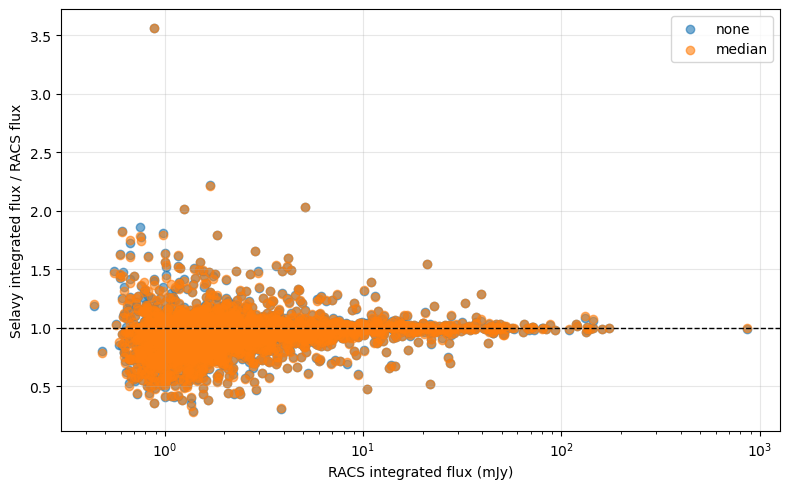

In [28]:
plot_mosaic_flux_ratios(("none", "median"))

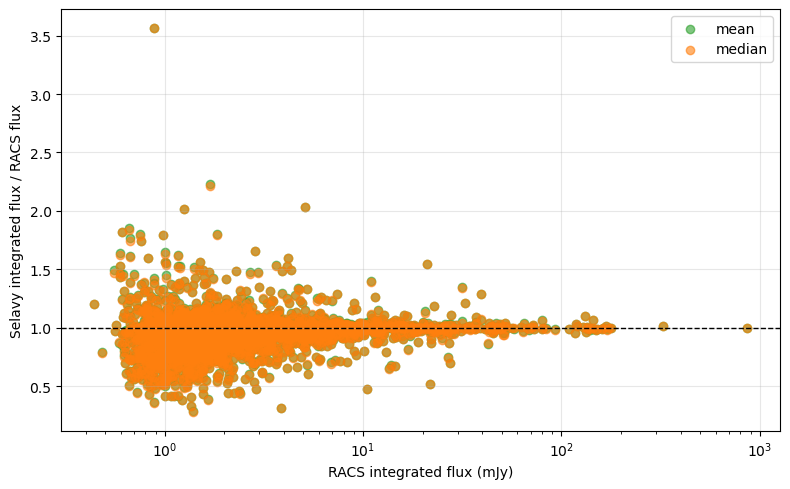

In [29]:
plot_mosaic_flux_ratios(("mean", "median"))

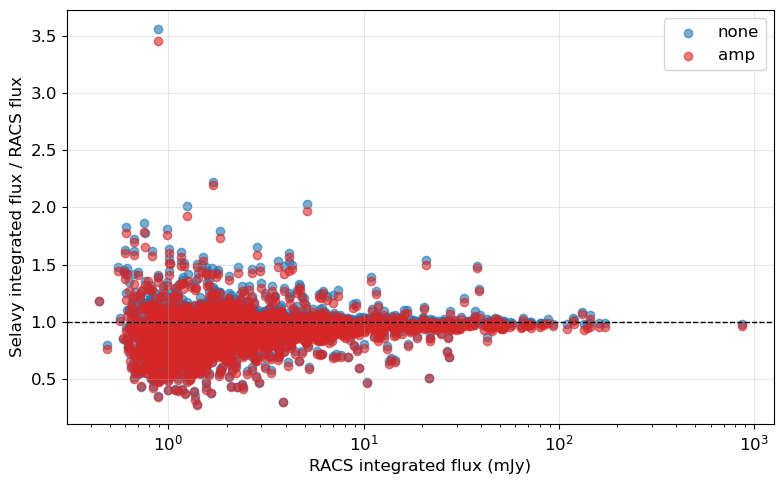

In [30]:
plt.rcParams.update({"font.size": 12})
plot_mosaic_flux_ratios(("none", "amp"))

In [31]:
cases = ("none", "median", "mean", "amp")

if not RACS_FILE.is_file():
    RACS_FILE = CSIRO / "science_field/skyModels/RACS-low3_flint_skymodel.fits.gz"

catalogues = {case: read_selavy(CATALOGUES / f"{case}-{MOSAIC_CATALOGUE}") for case in cases}
racs = read_racs_near_catalogues([selected for _, selected in catalogues.values()])
matches = {case: find_matches(racs, entries, selected) for case, (entries, selected) in catalogues.items()}
shared = set.intersection(*(set(matches[case]) for case in cases))

rows = []
for index in sorted(shared):
    separations = [matches[case][index][1] for case in cases]
    if max(separations) - min(separations) >= MATCH_ARCSEC:
        continue

    racs_flux = float(racs[index]["Total_flux"])
    ratios = np.array([matches[case][index][0]["integrated"] / racs_flux for case in cases])
    if np.all(np.isfinite(ratios) & (ratios > 0)):
        rows.append(ratios)

if not rows:
    raise ValueError("No shared sources with valid flux ratios in all four cases.")

medians = dict(zip(cases, np.median(rows, axis=0)))

print(f"Shared sources: {len(rows)}")
print(f"{'Case':<10} {'Median Selavy/RACS-low3':>23}")
for case, ratio in medians.items():
    print(f"{case:<10} {ratio:>23.4f}")

Shared sources: 2105
Case       Median Selavy/RACS-low3
none                        0.9609
median                      0.9598
mean                        0.9621
amp                         0.9352


# Leakage comparison

I select isolated sources with a Stokes I SNR greater than 10. I describe the method for Stokes Q and use the same procedure for U and V.

At each source position, I find the largest absolute pixel value in the Stokes Q image within a radius of 13 arcseconds, slightly smaller than the restoring beam’s FWHM. I divide that value by the source’s integrated Stokes I flux density from the Selavy catalogue.

At low SNR, the measurement is dominated by noise (This is seen if I lower the SNR threshold to 5 instead of 10). The peak absolute noise in the aperture is roughly independent of the source brightness, so the ratio falls approximately as 1/SNR. At high SNR, leakage can dominate. If the leaked signal scales with Stokes I, the ratio approaches a plateau. I use the level of that plateau to estimate the leakage fraction.

The plateau is clear for Stokes Q. For U and V, the ratios are lower and I have too few bright sources to constrain the plateau reliably (this is good - it means the leakage is very low).

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


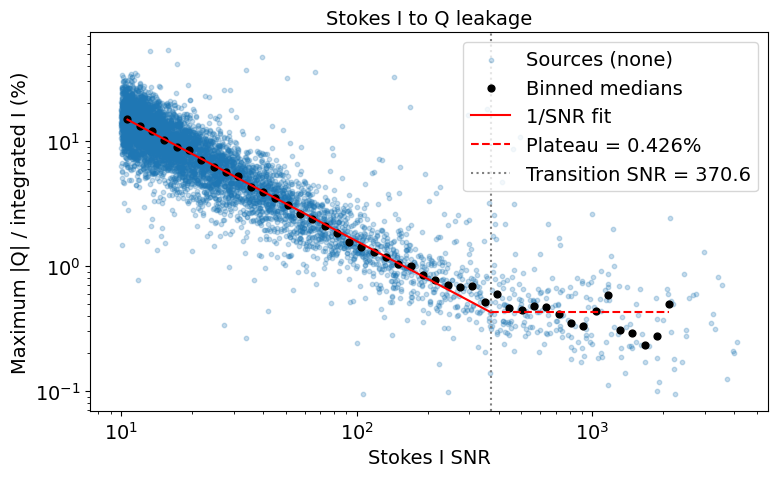

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


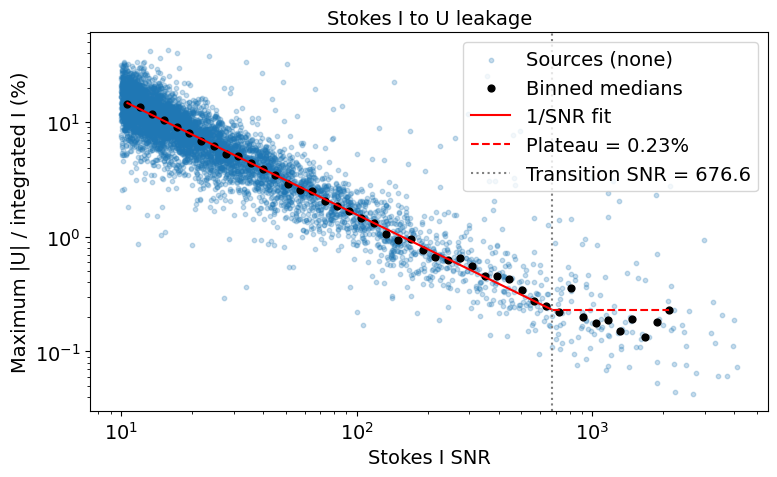

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


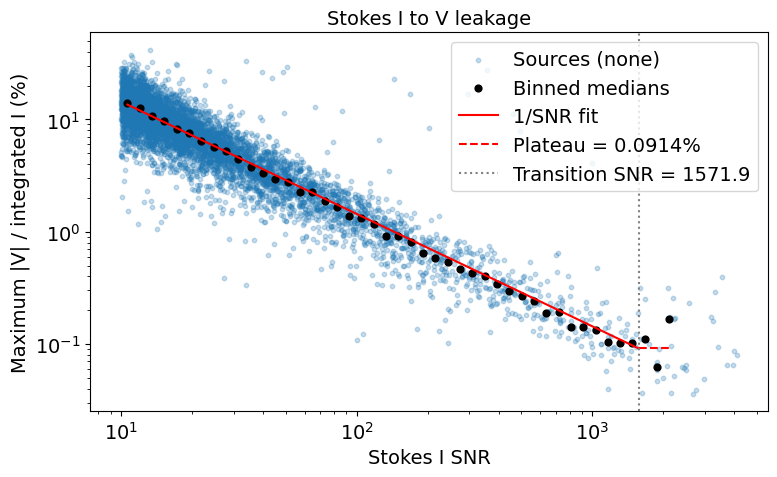

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


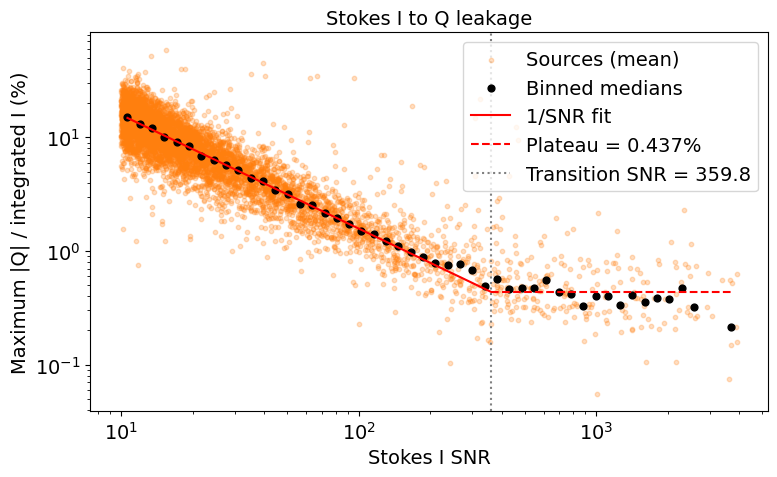

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


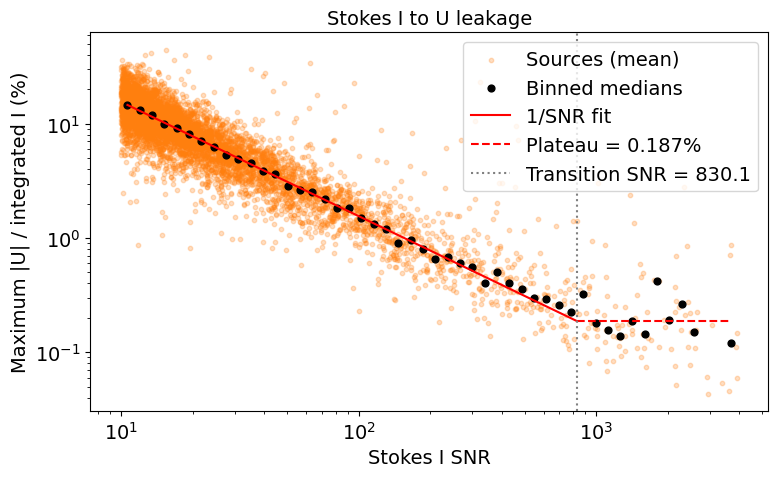

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


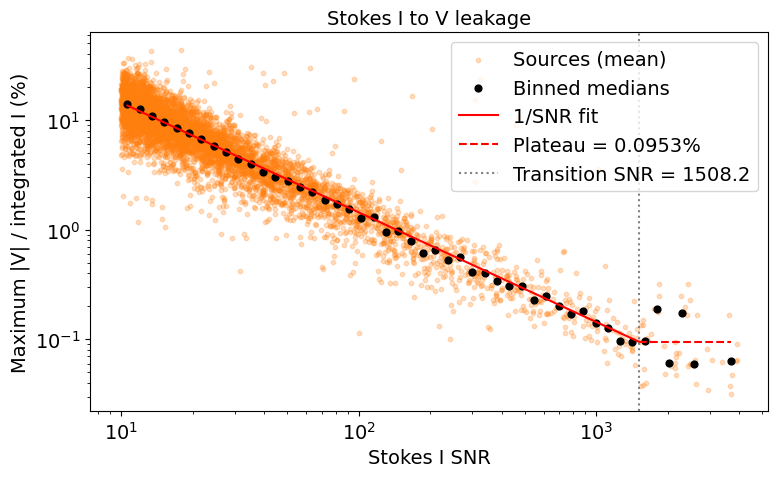

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


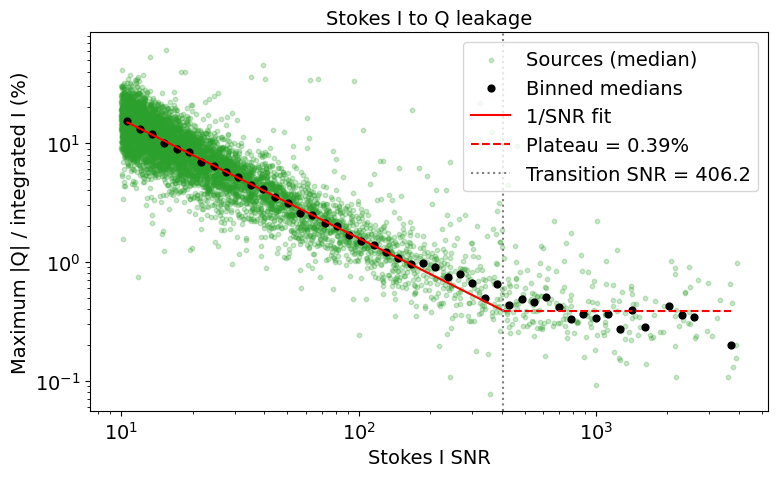

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


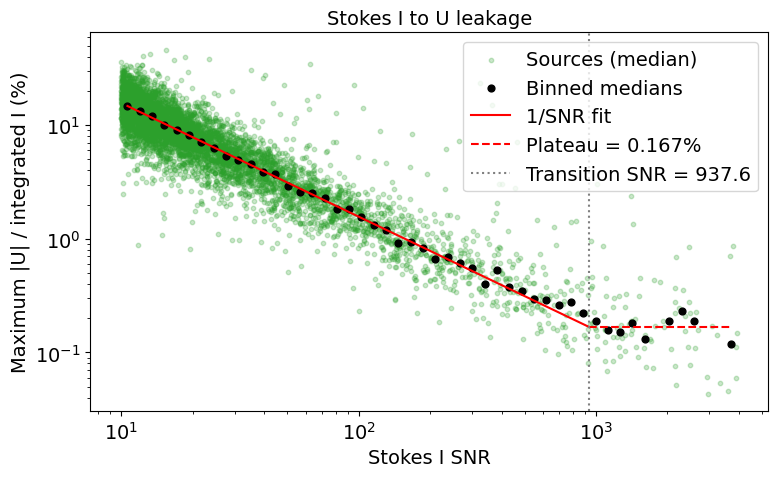

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


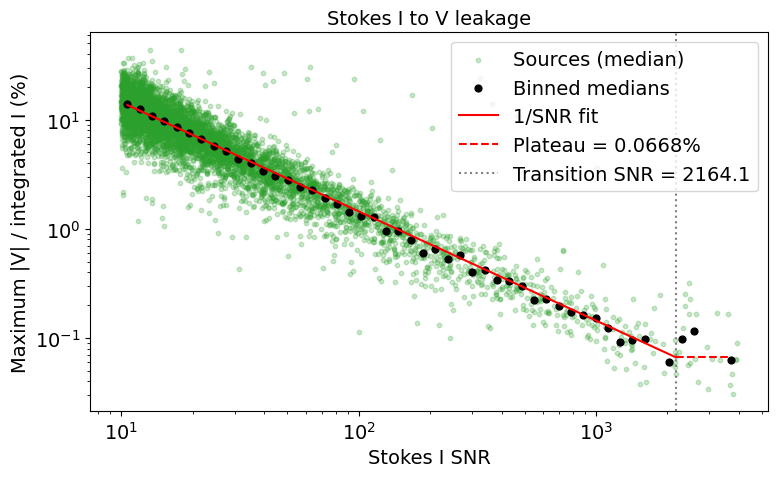

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


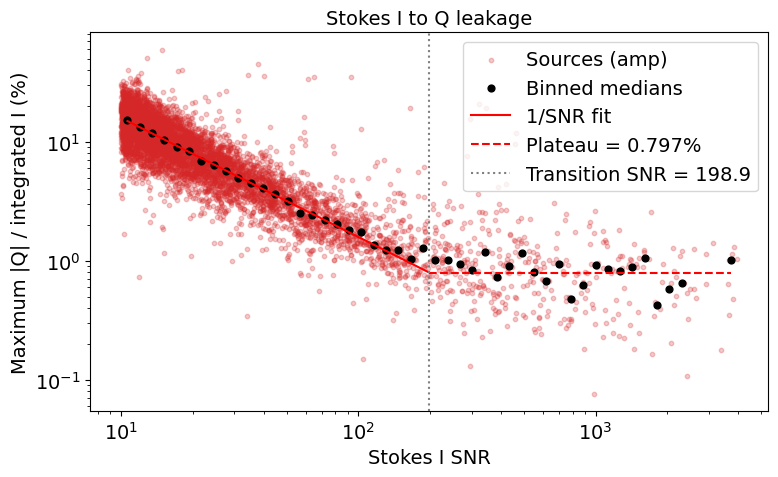

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


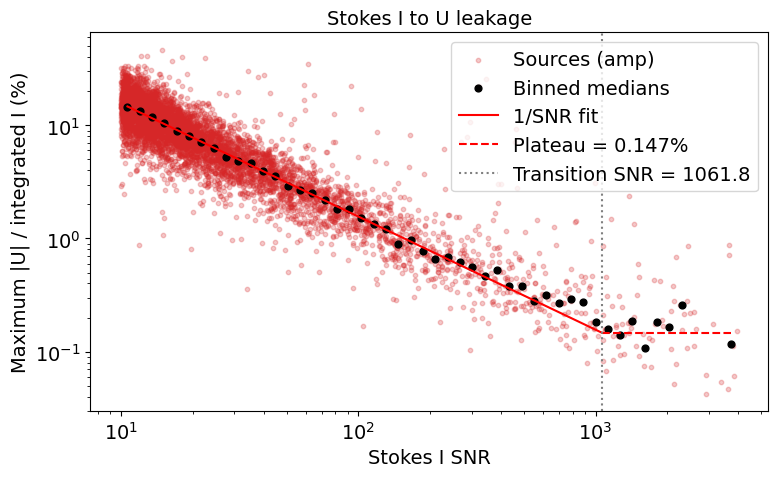

Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


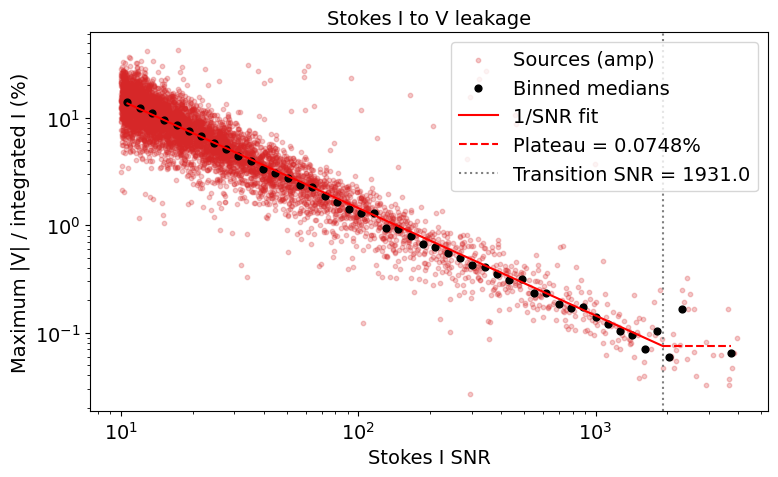

Case        I → Q (%)    I → U (%)    I → V (%)
none           0.4259       0.2303       0.0914
mean           0.4369       0.1871       0.0953
median         0.3898       0.1668       0.0668
amp            0.7972       0.1471       0.0748


In [32]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, search_around_sky
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales

plt.rcParams.update({"font.size": 14})
SCIENCE = Path.home() / "Documents/Australia/CSIRO/science_field"
PLOT_DIR = SCIENCE / "calibration_comparison_plots"
FIELD = "EMU_1014-46.SB87627.cont"

CASE_COLORS = {
    "none": "C0",
    "mean": "C1",
    "median": "C2",
    "amp": "C3",
}

MIN_SNR = 10.0
ISOLATION_ARCSEC = 45.0
APERTURE_ARCSEC = 13.0
SNR_BINS = 50
MIN_PER_BIN = 5


def read_catalogue(path):
    columns = None
    sources = []

    for line in path.read_text().splitlines():
        line = line.strip()
        if not line:
            continue

        if line.startswith("#"):
            header = line[1:].split()
            if "ra_deg_cont" in header and "flux_int" in header:
                columns = header
            continue

        if columns is None:
            continue

        row = dict(zip(columns, line.split()))

        try:
            peak = float(row["flux_peak"])
            rms = float(row["rms_image"])
            flux = float(row["flux_int"])
            ra = float(row["ra_deg_cont"])
            dec = float(row["dec_deg_cont"])
            siblings = int(float(row.get("has_siblings", 0)))
        except (KeyError, ValueError):
            continue

        if flux > 0 and rms > 0:
            sources.append((ra, dec, flux, peak / rms, siblings))

    if not sources:
        raise ValueError(f"No sources read from {path}")

    return np.asarray(sources)


def select_sources(sources):
    ra, dec, _, snr, siblings = sources.T
    coords = SkyCoord(ra, dec, unit="deg")
    first, second, _, _ = search_around_sky(coords, coords, ISOLATION_ARCSEC * u.arcsec)
    neighbors = np.bincount(first[first != second], minlength=len(sources))
    keep = (neighbors == 0) & (siblings == 0) & (snr >= MIN_SNR)
    return sources[keep]


def measure_fractions(sources, image_path):
    ra, dec, flux, snr, _ = sources.T
    coords = SkyCoord(ra, dec, unit="deg")
    fractions = np.full(len(sources), np.nan)

    with fits.open(image_path, memmap=True) as hdus:
        hdu = next(item for item in hdus if item.data is not None)
        image = np.squeeze(hdu.data)

        if image.ndim != 2:
            raise ValueError(f"Expected a 2D image in {image_path}, got {image.shape}")

        unit = hdu.header.get("BUNIT", "Jy/beam").lower()
        if "mjy" in unit:
            scale = 1
        elif "jy" in unit:
            scale = 1000
        else:
            raise ValueError(f"Unrecognised image unit in {image_path}: {unit}")

        wcs = WCS(hdu.header).celestial
        pixel_scale = np.sqrt(np.prod(proj_plane_pixel_scales(wcs) * 3600))
        radius = APERTURE_ARCSEC / pixel_scale
        xs, ys = wcs.world_to_pixel(coords)

        for i, (x, y) in enumerate(zip(xs, ys)):
            if not np.isfinite(x) or not np.isfinite(y):
                continue

            x0 = int(x - radius - 1)
            x1 = int(x + radius + 2)
            y0 = int(y - radius - 1)
            y1 = int(y + radius + 2)

            if x0 < 0 or y0 < 0 or x1 > image.shape[1] or y1 > image.shape[0]:
                continue

            yy, xx = np.ogrid[y0:y1, x0:x1]
            inside = np.hypot(xx - x, yy - y) <= radius
            pixels = image[y0:y1, x0:x1][inside]
            pixels = pixels[np.isfinite(pixels)]

            if pixels.size:
                fractions[i] = scale * np.max(np.abs(pixels)) / flux[i]

    valid = np.isfinite(snr) & np.isfinite(fractions) & (fractions > 0)
    return snr[valid], fractions[valid]


def fit_leakage(sources, image_path, case, stokes, plot=True):
    snr, fractions = measure_fractions(sources, image_path)

    if snr.size < 2 or snr.min() == snr.max():
        raise ValueError(f"Too few usable SNR values in {image_path}")

    edges = np.geomspace(snr.min(), snr.max(), SNR_BINS + 1)
    bin_ids = np.searchsorted(edges[1:-1], snr, side="right")
    centres = []
    medians = []
    errors = []

    for index in range(SNR_BINS):
        values = fractions[bin_ids == index]
        if values.size < MIN_PER_BIN:
            continue

        median = np.median(values)
        error = np.std(values) / np.sqrt(values.size)

        if median > 0 and error > 0:
            centres.append(np.sqrt(edges[index] * edges[index + 1]))
            medians.append(median)
            errors.append(error)

    if len(centres) < 8:
        raise ValueError(f"Too few populated SNR bins to fit {image_path}")

    centres = np.asarray(centres)
    medians = np.asarray(medians)
    errors = np.asarray(errors)
    x = np.log10(centres)
    y = np.log10(medians)
    log_error = errors / (medians * np.log(10))
    weights = 1 / log_error**2
    best_chi2 = np.inf

    for split in range(3, len(x) - 2):
        break_x = (x[split - 1] + x[split]) / 2
        shape = np.maximum(break_x - x, 0)
        level = np.average(y - shape, weights=weights)
        chi2 = np.sum(weights * (y - level - shape)**2)

        if chi2 < best_chi2:
            best_chi2 = chi2
            best_level = level
            best_break = break_x

    transition_snr = float(10**best_break)
    leakage_pct = float(100 * 10**best_level)

    if plot:
        PLOT_DIR.mkdir(parents=True, exist_ok=True)

        falling_snr = np.geomspace(centres.min(), transition_snr, 150)

        fig, ax = plt.subplots(figsize=(8, 5))
        ax.scatter(snr, 100 * fractions, s=10, alpha=0.25, color=CASE_COLORS[case], label=f"Sources ({case})")
        ax.scatter(centres, 100 * medians, s=24, color="black", label="Binned medians")
        ax.plot(falling_snr, leakage_pct * transition_snr / falling_snr, color="red", linestyle="-", label="1/SNR fit")
        ax.plot([transition_snr, centres.max()], [leakage_pct, leakage_pct], color="red", linestyle="--", label=f"Plateau = {leakage_pct:.3g}%")
        ax.axvline(transition_snr, color="gray", linestyle=":", label=f"Transition SNR = {transition_snr:.1f}")
        # ax.axhline(leakage_pct, color="red", linestyle="--", label=f"Plateau = {leakage_pct:.3g}%")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Stokes I SNR")
        ax.set_ylabel(f"Maximum |{stokes}| / integrated I (%)")
        ax.set_title(f"Stokes I to {stokes} leakage", fontsize=14)
        ax.legend()
        fig.tight_layout()

        filename = f"SB87627_mosaic_leakage_{case}_I-to-{stokes}_fit.pdf"
        fig.savefig(PLOT_DIR / filename, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    return {
        "leakage_percent": leakage_pct,
        "transition_snr": transition_snr,
        "n_sources": int(snr.size),
    }


def print_leakage_table(cases=("none", "mean", "median", "amp"), plot=True):
    results = {}

    for case in cases:
        catalogue_name = f"{case}-selavy-image.i.{FIELD}.taylor.0.restored.conv.components.txt"
        catalogue_path = SCIENCE / "sourceCatalogues" / catalogue_name
        sources = select_sources(read_catalogue(catalogue_path))

        if not len(sources):
            raise ValueError(f"No sources passed the cuts for {case}")

        results[case] = {}

        for stokes in ("Q", "U", "V"):
            image_name = f"image.{stokes.lower()}.{FIELD}.EMU_1014-46.linmos.taylor.0.restored.conv.fits"
            image_path = SCIENCE / "images" / case / image_name
            results[case][stokes] = fit_leakage(sources, image_path, case, stokes, plot=plot)

    print(f"{'Case':<8} {'I → Q (%)':>12} {'I → U (%)':>12} {'I → V (%)':>12}")

    for case, values in results.items():
        q = values["Q"]["leakage_percent"]
        u_pct = values["U"]["leakage_percent"]
        v = values["V"]["leakage_percent"]
        print(f"{case:<8} {q:12.4f} {u_pct:12.4f} {v:12.4f}")

    return results


leakage_results = print_leakage_table()

# In the images

The images seem to improve around bright sources. It's not perfect, but the noise is decreasing. Here I only show none vs median vs mean. The case where I do not normalize the amplitudes seem to change the flux scale and worsen the leakage, which is something we do not want in the data.

In [3]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from astropy.io import fits
from astropy.wcs import WCS
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
import astropy.units as u
plt.rcParams.update({"font.size": 16})

BASE = Path.home() / "Documents/Australia/CSIRO/science_field/images"
FILENAME = "image.i.EMU_1014-46.SB87627.cont.EMU_1014-46.linmos.taylor.0.restored.conv.fits"
files = {name: BASE / f"{name}" / FILENAME for name in ("none", "median", "mean")}

for name, path in files.items():
    print(name, path.exists())


def compare_images(ra, dec, size=20, vlim=1.0, cmap="magma", save=None, noise_size=3, noise_east=5, noise_north=5):
    position = SkyCoord(ra=ra * u.deg, dec=dec * u.deg, frame="icrs")
    noise_position = position.spherical_offsets_by(noise_east * u.arcmin, noise_north * u.arcmin)
    norm = TwoSlopeNorm(vmin=-vlim, vcenter=0, vmax=vlim)

    fig = plt.figure(figsize=(15, 5))
    rms_values = {}

    for i, (name, filename) in enumerate(files.items()):
        with fits.open(filename, memmap=True) as hdul:
            data = np.squeeze(hdul[0].data)
            wcs = WCS(hdul[0].header).celestial

            cutout = Cutout2D(data, position, size * u.arcmin, wcs=wcs, mode="partial", fill_value=np.nan)
            image = cutout.data * 1000

            noise = Cutout2D(data, noise_position, noise_size * u.arcmin, wcs=wcs, mode="partial", fill_value=np.nan)
            pixels = noise.data[np.isfinite(noise.data)] * 1000
            rms = np.std(pixels) if pixels.size else np.nan
            rms_values[name] = rms

        print(f"{name:<12} RMS = {rms:.4f} mJy/beam")

        ax = fig.add_subplot(1, len(files), i + 1, projection=cutout.wcs)
        im = ax.imshow(image, origin="lower", cmap=cmap, norm=norm, interpolation="nearest")
        ax.set_title(f"{name.capitalize()}", fontsize=15)
        ax.set_xlabel("RA")

        if i == 0:
            ax.set_ylabel("DEC")
        else:
            ax.set_ylabel("")
            ax.coords[1].set_ticklabel_visible(False)

    fig.subplots_adjust(left=0.07, right=0.88, bottom=0.12, top=0.85, wspace=0.12)
    cax = fig.add_axes([0.90, 0.17, 0.015, 0.63])
    fig.colorbar(im, cax=cax).set_label("Flux density (mJy/beam)")

    if save:
        fig.savefig(save, dpi=300, bbox_inches="tight")

    plt.show()

    return rms_values

none True
median True
mean True


Source 1
none         RMS = 0.0982 mJy/beam


Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


median       RMS = 0.0709 mJy/beam
mean         RMS = 0.0712 mJy/beam


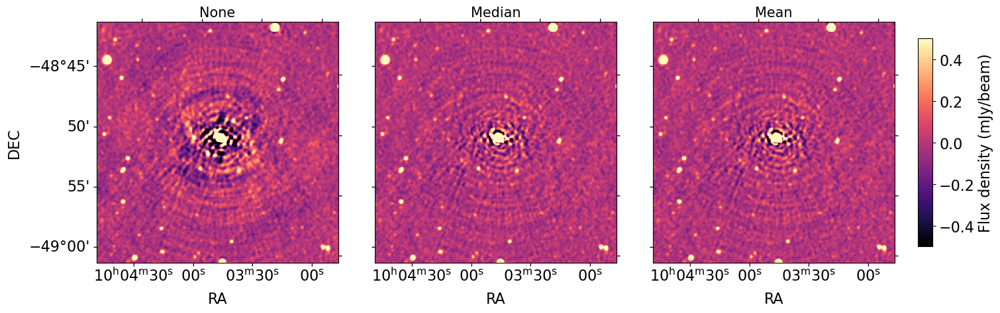

Source 2
none         RMS = 0.0509 mJy/beam
median       RMS = 0.0347 mJy/beam


Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


mean         RMS = 0.0349 mJy/beam


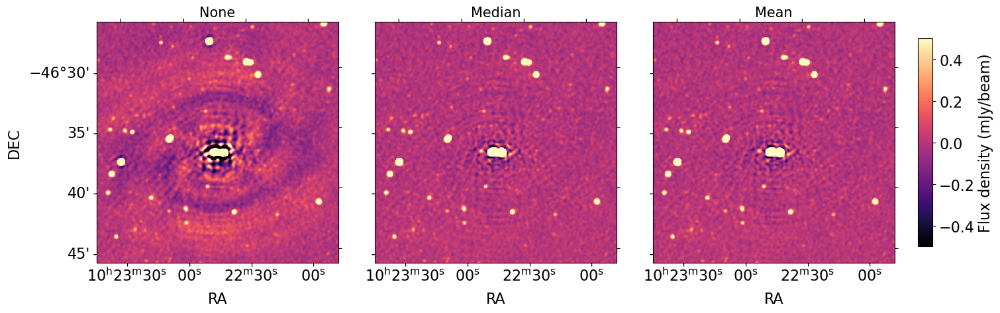

Source 3
none         RMS = 0.0802 mJy/beam


Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


median       RMS = 0.0548 mJy/beam
mean         RMS = 0.0546 mJy/beam


Set OBSGEO-B to   -26.704100 from OBSGEO-[XYZ].
Set OBSGEO-H to      121.995 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


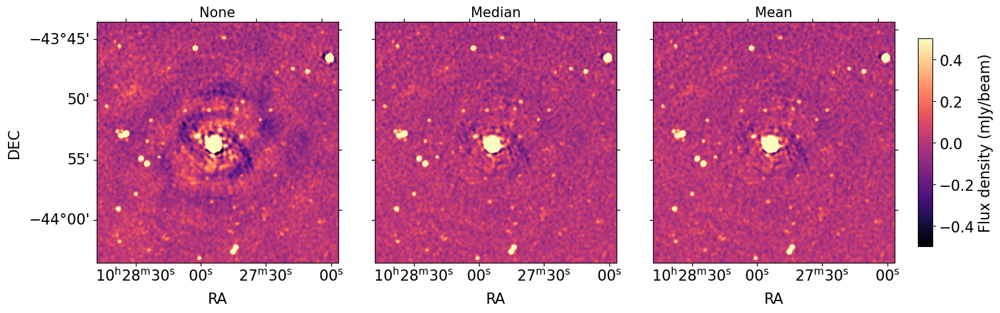

In [4]:
sources = {"Source 1": ("10h03m50s", "-48d51m00s"), "Source 2": ("10h22m45s", "-46d36m00s"), "Source 3": ("10h27m50s", "-43d54m00s")}

plot_dir = Path.home() / "Documents/Australia/CSIRO/science_field/comparison_images"
plot_dir.mkdir(parents=True, exist_ok=True)

for name, (ra, dec) in sources.items():
    coord = SkyCoord(ra, dec)
    print(name)
    compare_images(ra=coord.ra.deg, dec=coord.dec.deg, size=20, vlim=0.5, noise_size=3, noise_east=3, noise_north=3, save=plot_dir / f"{name.replace(' ', '_')}.pdf")